import kagglehub

# Download latest version
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")

print("Path to dataset files:", path)

import pandas as pd

df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [6]:
df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


Part 1

In [42]:
#checking the top 10 categpries by value counts, in ascending order
frequency_table = df['category'].value_counts().head(10).sort_values(ascending=False)
print(frequency_table)

category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Manicure & Pedicure Products               18940
Skin Care                                  18769
Make-up                                    18756
Hair Care                                  18735
Fragrances                                 18564
Name: count, dtype: int64


Sports & Outdoors is by far the most listed category, with over 836,000 products.
The next most popular categories (Beauty, Handmade Clothing, Bath & Body, and Birthday Gifts) each have between +18,000 and +19,000 listings, showing relatively small variation among them.
This suggests that, apart from the dominant Sports & Outdoors segment, the remaining top categories are balanced in terms of listing.

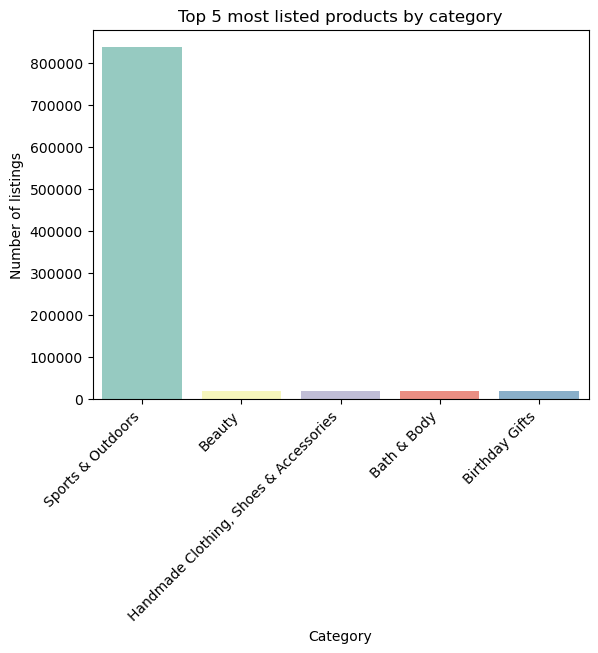

In [45]:
import seaborn as sns
import matplotlib.pyplot as plt

#filtering by the top 5 categories
top_categories = frequency_table.head(5)

#creating the bar chart, defining axes and labels
sns.barplot(
    x=top_categories.index,
    y=top_categories.values,
    hue=top_categories.index,
    palette="Set3",
    legend=False
)

plt.xticks(rotation=45, ha='right')
plt.xlabel("Category")
plt.ylabel("Number of listings")
plt.title("Top 5 most listed products by category")
plt.show()

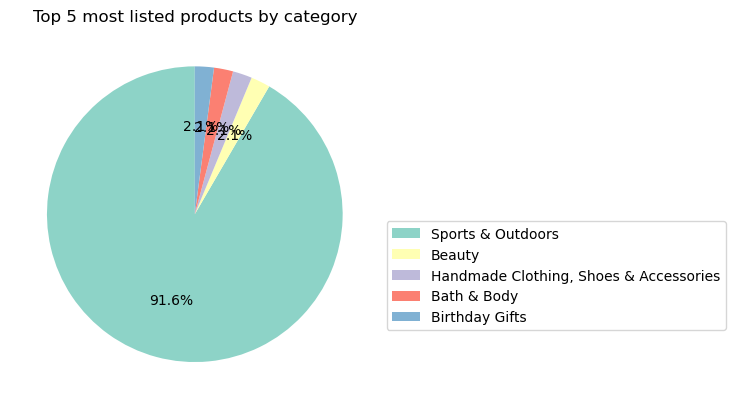

In [46]:
#filtering by the top 5 categories
top5 = frequency_table.head(5)

#creating the pie chart, style and legend
plt.pie(
    top5.values,
    labels=None,
    autopct='%1.1f%%',
    startangle=90,
    colors=sns.color_palette("Set3", n_colors=5)
)
plt.title("Top 5 most listed products by category")
plt.legend(top5.index, loc="best", bbox_to_anchor=(1, 0.5))
plt.show()

The pie chart clarifies that Sports & Outdoors accounts for 91.6% of all products

Part 2

In [48]:
#calculating measures of centrality
mean_price = round(df['price'].mean(), 2)
median_price = df['price'].median()
mode_price = df['price'].mode()[0]

print(f"Mean price: {mean_price}")
print(f"Median price: {median_price}")
print(f"Mode price: {mode_price}")

Mean price: 89.24
Median price: 19.09
Mode price: 9.99


The most common product price, 9.99, is relatively low compared to the average price, 89.24.
This gap between the mode and the mean suggests that while most products are quite affordable, there are a few items priced significantly higher, increasing the average.
In other words, the price distribution is right-skewed, with a small number of very expensive products influencing the overall average.

In [49]:
#creating a new dataset and filtering out all nan values and any prices below 1
df_clean = df[df['price'].notna() & (df['price'] > 0)].copy()

#calculating measures of dispersion
variance_price = round(df_clean['price'].var(), 2)
std_dev_price = round(df_clean['price'].std(), 2)
min_price = df_clean['price'].min()
max_price = df_clean['price'].max()
range_price = max_price - min_price
quantiles_price = df_clean['price'].quantile([0.25, 0.5, 0.75])

print(f"Variance price: {variance_price}")
print(f"Standard deviation price: {std_dev_price}")
print(f"Range price: {range_price}")
print(f"Quantile price: {quantiles_price}")
print(min_price)

Variance price: 119446.4
Standard deviation price: 345.61
Range price: 99999.99
Quantile price: 0.25     9.99
0.50    19.09
0.75    45.99
Name: price, dtype: float64
0.01


The measures of dispersion show that 75% of products are priced below approximately 46, while the maximum price reaches 100,000.
This extremely wide range and the very high standard deviation confirm a highly uneven price distribution.
The data suggest that although the vast majority of products are low-priced, a small number of very expensive items significantly affect the overall spread of prices.

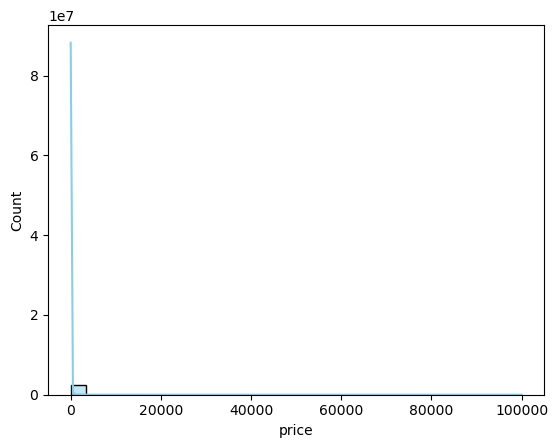

In [58]:
#histogram
sns.histplot(df['price'], kde=True, bins=30, color="skyblue")
plt.show()

Both the histogram and bixplot are difficult to interpret because the majority of products are priced below 500, while a few outliers reach up to 100,000. These extremely high prices distort the scale, making the lower-priced products appear compressed near zero.

To make these visualizations more meaningful, we can limit the price range, for example, focusing on items between 0 and 500

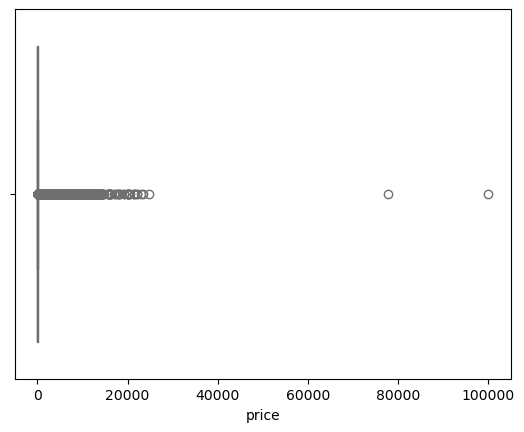

In [59]:
#boxplot
sns.boxplot(x=df_clean['price'], color='skyblue')
plt.show()

Part 3

In [61]:
#creating a new dataset and filtering out all nan values for stars and values equal to 0 
df_clean = df[df['stars'].notna() & (df['stars'] > 0)].copy()

mean_rating = round(df_clean['stars'].mean(), 2)
median_rating = df_clean['stars'].median()
mode_rating = df_clean['stars'].mode()[0]

print(f"Mean rating: {mean_rating}")
print(f"Median rating: {median_rating}")
print(f"Mode rating: {mode_rating}")

Mean rating: 4.32
Median rating: 4.4
Mode rating: 4.5


After filtering out missing and zero values, the average product rating is 4.32, with a median of 4.4 and a mode of 4.5.
These values are all very close to each other and clustered near the upper end of the 5-point scale, indicating that most customers leave positive reviews.
The high mode of 4.5 further confirms that the most frequent rating given by users is quite high, suggesting overall customer satisfaction with the products.

In [63]:
variance_rating = round(df_clean['stars'].var(), 2)
std_dev_rating = round(df_clean['stars'].std(), 2)
min_rating = df_clean['stars'].min()
max_rating = df_clean['stars'].max()
range_rating = max_rating - min_rating
quantiles_rating = df_clean['stars'].quantile([0.25, 0.5, 0.75])

print(f"Variance rating: {variance_rating}")
print(f"Standard deviation rating: {std_dev_rating}")
print(f"Range rating: {range_rating}")
print(f"Quantile rating: {quantiles_rating}")
print(min_rating)

Variance rating: 0.31
Standard deviation rating: 0.56
Range rating: 4.0
Quantile rating: 0.25    4.1
0.50    4.4
0.75    4.6
Name: stars, dtype: float64
1.0


The measures of dispersion show that 75% of product ratings are above 4.1, confirming the vast majority of reviews are very positive

In [67]:
skewness_rating = df_clean['stars'].skew()
kurtosis_rating = df_clean['stars'].kurtosis()

print(f"Skewness of rating: {skewness_rating}")
print(f"Kurtosis of rating: {kurtosis_rating}")

Skewness of rating: -2.3795681122127945
Kurtosis of rating: 9.78193769066435


The negative skewness (-2.38) indicates that the vast majority of products receive high ratings, with only a small number of poorly rated items pulling the tail to the left.

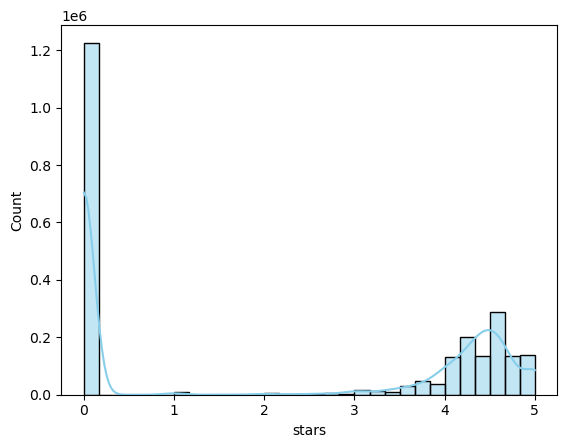

In [65]:
sns.histplot(df['stars'], kde=True, bins=30, color="skyblue")
plt.show()

I created a histogram without filtering out 0 values, which shows that most people didn’t leave any reviews. This would have made a huge difference in the measures of central tendency and dispersion, as the large number of zeros would pull the average rating down and distort the overall distribution.

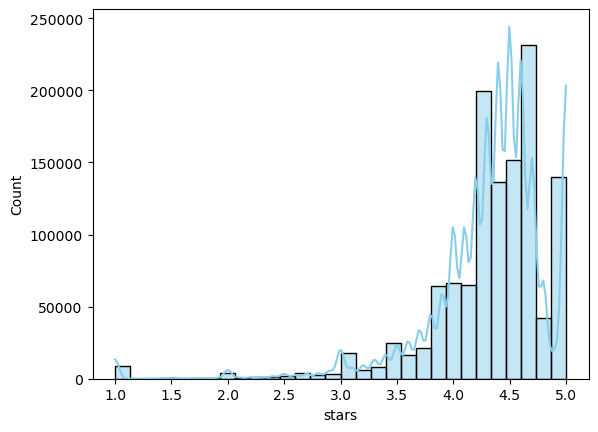

In [66]:
sns.histplot(df_clean['stars'], kde=True, bins=30, color="skyblue")
plt.show()